# zomato EDA 

## installing seaborn and matpoltlib library


In [2]:
pip install matplotlib


Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 26.1.2 -> 26.3
[notice] To update, run: python.exe -m pip install --upgrade pip


In [5]:
pip install seaborn

Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 26.1.2 -> 26.3
[notice] To update, run: python.exe -m pip install --upgrade pip


In [12]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [13]:
df = pd.read_csv("zomato_data.csv")

In [16]:
df.head(5)

,Restaurant Name,Online_Order,Book_Table,Rate,Votes,Approx_Cost(For Two People),Listed_In(Type)
0,Jalsa,Yes,Yes,4.1/5,775,800,Buffet
1,Spice Elephant,Yes,No,4.1/5,787,800,Buffet
2,San Churro Cafe,Yes,No,3.8/5,918,800,Buffet
3,Addhuri Udupi Bhojana,No,No,3.7/5,88,300,Buffet
4,Grand Village,No,No,3.8/5,166,600,Buffet


In [18]:
df.shape

(148, 7)

In [20]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 148 entries, 0 to 147
Data columns (total 7 columns):
 #   Column                       Non-Null Count  Dtype
---  ------                       --------------  -----
 0   Restaurant Name              148 non-null    str  
 1   Online_Order                 148 non-null    str  
 2   Book_Table                   148 non-null    str  
 3   Rate                         148 non-null    str  
 4   Votes                        148 non-null    int64
 5   Approx_Cost(For Two People)  148 non-null    int64
 6   Listed_In(Type)              148 non-null    str  
dtypes: int64(2), str(5)
memory usage: 8.2 KB


In [22]:
df.describe(include='all')

,Restaurant Name,Online_Order,Book_Table,Rate,Votes,Approx_Cost(For Two People),Listed_In(Type)
count,148,148,148,148,148.000000,148.000000,148
unique,145,2,2,20,NaN,NaN,4
top,San Churro Cafe,No,No,3.8/5,NaN,NaN,Dining
freq,2,90,140,19,NaN,NaN,110
mean,NaN,NaN,NaN,NaN,264.810811,418.243243,NaN
std,NaN,NaN,NaN,NaN,653.676951,223.085098,NaN
min,NaN,NaN,NaN,NaN,0.000000,100.000000,NaN
25%,NaN,NaN,NaN,NaN,6.750000,200.000000,NaN
50%,NaN,NaN,NaN,NaN,43.500000,400.000000,NaN
75%,NaN,NaN,NaN,NaN,221.750000,600.000000,NaN


In [26]:
def handleRate(value):
    value = str(value).split("/")
    value = value[0]
    return float(value)
df["Rate"] = df["Rate"].apply(handleRate)
print(df.head(5))
df.info()

         Restaurant Name Online_Order Book_Table  Rate  Votes  \
0                  Jalsa          Yes        Yes   4.1    775   
1         Spice Elephant          Yes         No   4.1    787   
2        San Churro Cafe          Yes         No   3.8    918   
3  Addhuri Udupi Bhojana           No         No   3.7     88   
4          Grand Village           No         No   3.8    166   

   Approx_Cost(For Two People) Listed_In(Type)  
0                          800          Buffet  
1                          800          Buffet  
2                          800          Buffet  
3                          300          Buffet  
4                          600          Buffet  
<class 'pandas.DataFrame'>
RangeIndex: 148 entries, 0 to 147
Data columns (total 7 columns):
 #   Column                       Non-Null Count  Dtype  
---  ------                       --------------  -----  
 0   Restaurant Name              148 non-null    str    
 1   Online_Order                 148 non-null  

In [31]:
df.columns = df.columns.str.lower()
df.columns

Index(['restaurant name', 'online_order', 'book_table', 'rate', 'votes',
       'approx_cost(for two people)', 'listed_in(type)'],
      dtype='str')

In [33]:
df.rename(
    columns={"approx_cost(for two people)": "approx_cost"},
    inplace=True
)

In [34]:
df.columns

Index(['restaurant name', 'online_order', 'book_table', 'rate', 'votes',
       'approx_cost', 'listed_in(type)'],
      dtype='str')

In [35]:
print("Missing values:")
print(df.isnull().sum())
print("Duplicate Rows:", df.duplicated().sum())

Missing values:
restaurant name    0
online_order       0
book_table         0
rate               0
votes              0
approx_cost        0
listed_in(type)    0
dtype: int64
Duplicate Rows: 0


In [36]:
grouped_data = df.groupby("listed_in(type)")["votes"].sum()
grouped_data

listed_in(type)
Buffet     3028
Cafes      6434
Dining    20363
other      9367
Name: votes, dtype: int64

In [37]:
result = df["book_table"].value_counts()
result

book_table
No     140
Yes      8
Name: count, dtype: int64

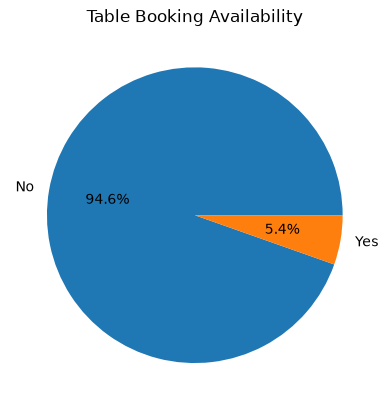

In [38]:
result.plot.pie(autopct="%1.1f%%")
plt.title("Table Booking Availability")
plt.show()

In [39]:
top5 = df.nlargest(5, "votes")
print(top5[["restaurant name", "votes"]])

      restaurant name  votes
38  Empire Restaurant   4884
86      Meghana Foods   4401
7              Onesta   2556
44             Onesta   2556
65        Kabab Magic   1720


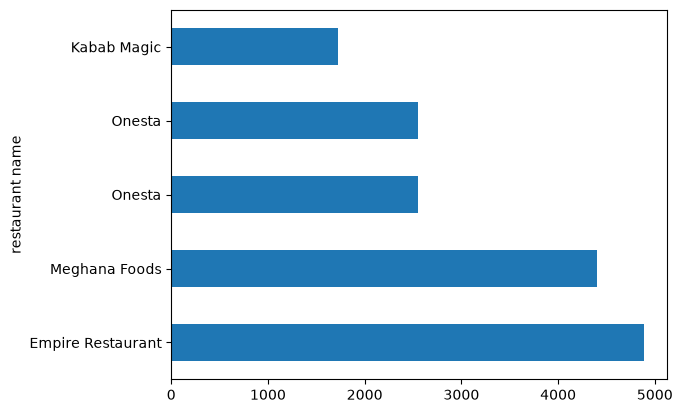

In [40]:
top5.plot.barh(x="restaurant name", y="votes", legend=False)
plt.show()

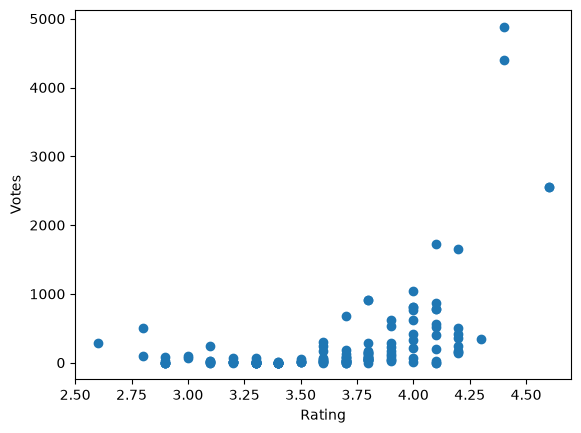

In [41]:
plt.scatter(df["rate"], df["votes"])
plt.xlabel("Rating")
plt.ylabel("Votes")
plt.show()

In [42]:
result = df.groupby("listed_in(type)")["rate"].mean()
print(result.sort_values(ascending=False))

listed_in(type)
other     3.912500
Buffet    3.842857
Cafes     3.765217
Dining    3.571818
Name: rate, dtype: float64


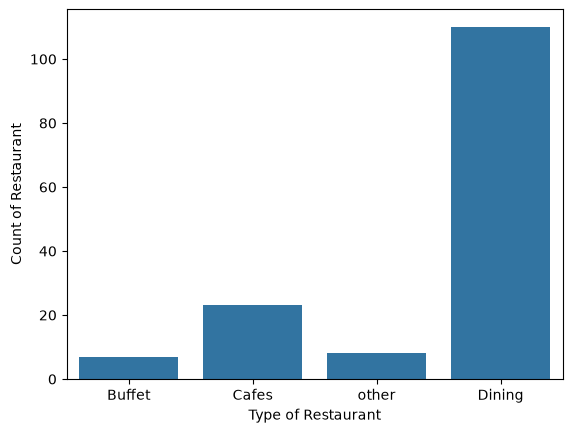

In [43]:
sns.countplot(x=df["listed_in(type)"])
plt.xlabel("Type of Restaurant")
plt.ylabel("Count of Restaurant")
plt.show()

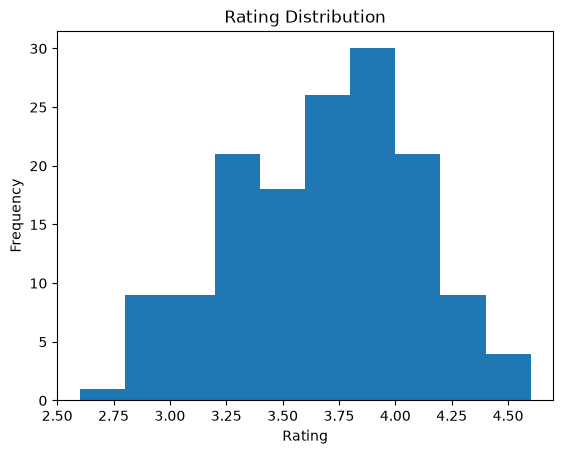

In [44]:
plt.hist(df["rate"], bins=10)
plt.title("Rating Distribution")
plt.xlabel("Rating")
plt.ylabel("Frequency")
plt.show()

In [45]:
result = df.groupby("listed_in(type)")["approx_cost"].mean()
result.sort_values(ascending=False)

listed_in(type)
Buffet    671.428571
other     668.750000
Cafes     545.652174
Dining    357.272727
Name: approx_cost, dtype: float64

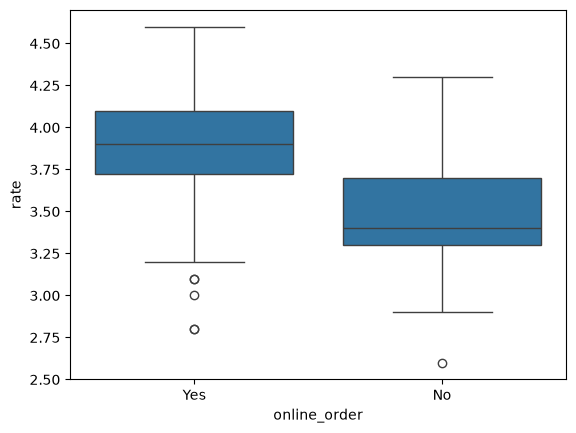

In [46]:
sns.boxplot(x="online_order", y="rate", data=df)
plt.show()

In [48]:
pivot_table = df.pivot_table(
index="listed_in(type)",
columns="online_order",
aggfunc="size",
fill_value=0
)
pivot_table

online_order,No,Yes
listed_in(type),,
Buffet,3,4
Cafes,8,15
Dining,77,33
other,2,6


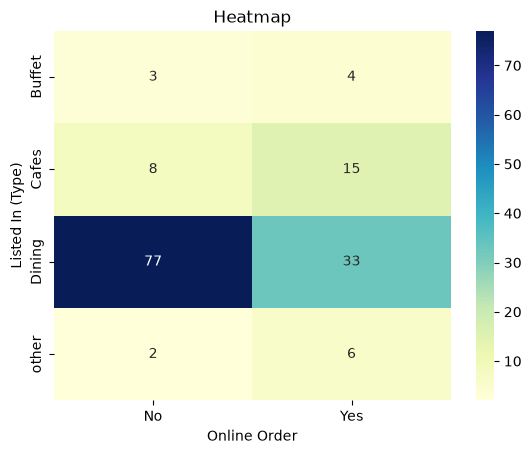

In [49]:
sns.heatmap(pivot_table, annot=True, cmap="YlGnBu", fmt="d")
plt.title("Heatmap")
plt.xlabel("Online Order")
plt.ylabel("Listed In (Type)")
plt.show()